# Simulazione finale

Si caricano le librerie necessarie e la solita shape

In [1]:
from QuantumCompiling import CircuitState,CircuitShape
import scipy.sparse as sp
import numpy as np
import csv
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import time
import itertools
import matplotlib.ticker as ticker
import math
import os
import datetime
import ast

In [2]:
n_qubits = 4
gates = { 
    1 : [ ["ID"] ],                         #0
    2 : [   ["Sc","St"],                    #1
            ["CZc","CZt"] ],                #2
    3 : [ ["CZc","ID","CZt"] ],             #3
    4 : [ ["CZc","CZc","CZt","CZt"] ]       #4
}

infidelities = [0,0,1,1.5,5]   #riscalo infidelity (10^-3) e conseguentemente i tempi
crosstalks = [
    [0,0,0,0,0],
    [0,0,0,0,0],
    [0,0,1,0,0],
    [0,0,0,0,0],
    [0,0,0,0,0]
]

shape = CircuitShape(n_qubits,gates,infidelities=infidelities,crosstalks=crosstalks,eq_dir="../EQUIVALENZE/equivalenze")
shape.print_steps(); 

0: ['ID', 'ID', 'ID', 'ID']		 Inf.=0
1: ['ID', 'ID', 'Sc', 'St']		 Inf.=0
2: ['ID', 'ID', 'CZc', 'CZt']		 Inf.=1
3: ['ID', 'Sc', 'St', 'ID']		 Inf.=0
4: ['ID', 'CZc', 'CZt', 'ID']		 Inf.=1
5: ['ID', 'CZc', 'ID', 'CZt']		 Inf.=1.5
6: ['Sc', 'St', 'ID', 'ID']		 Inf.=0
7: ['Sc', 'St', 'Sc', 'St']		 Inf.=0
8: ['Sc', 'St', 'CZc', 'CZt']		 Inf.=1
9: ['CZc', 'CZt', 'ID', 'ID']		 Inf.=1
10: ['CZc', 'CZt', 'Sc', 'St']		 Inf.=1
11: ['CZc', 'CZt', 'CZc', 'CZt']		 Inf.=3
12: ['CZc', 'ID', 'CZt', 'ID']		 Inf.=1.5
13: ['CZc', 'CZc', 'CZt', 'CZt']		 Inf.=5



Si aggiunge ora un metodo alla classe CircuitOperatoins per fare la simulazione finale. Ci sarà un metodo che simula e salva i riultati su file ed un altro che li legge

In [3]:
class Plotter:
    def plot_evolution(dt_d,dt_i,Nd,Ni,infidelities_d,infidelities_i,dev_stds_d, dev_stds_i,p0, population):
        t_d = [dt_d*i for i in range(Nd)] 
        t_i = [t_d[-1] + dt_i*i for i in range(Ni)]
        t_tot = t_d + t_i
        
        fig = plt.figure(figsize=(12, 8))
        gs = gridspec.GridSpec(2, 2, height_ratios=[4, 1], width_ratios=[1, 1])
        
        fig.suptitle("State evolution")

        ax1 = plt.subplot(gs[0])
        ax2 = plt.subplot(gs[1])
        ax3 = plt.subplot(gs[2])
        ax4 = plt.subplot(gs[3])

        x_min_d = 0-t_d[-1]/25
        x_max_d = t_d[-1] + t_d[-1]/25
        x_min_i = t_d[-1]- (t_i[-1]-t_d[-1])/25
        x_max_i= t_i[-1] + (t_i[-1]-t_d[-1])/25
        
        y_min = 0
        y_max = max(infidelities_d+infidelities_i)+max(dev_stds_d+dev_stds_i)+1
        
        ax1.errorbar(t_d, infidelities_d, yerr=dev_stds_d, fmt='o', capsize=3, color=(0, 0, 179/255))
        ax1.set_xlabel(r't')
        ax1.set_ylabel(r'Infidelity')
        ax1.set_title(r'Time evolution')
        ax1.set_xlim(x_min_d, x_max_d)
        ax1.set_ylim(y_min, y_max)
        ax1.grid(True)
        
        ax2.errorbar(t_i, infidelities_i, yerr=dev_stds_i, fmt='o',color=(230/255, 46/255, 0),capsize=5)
        ax2.set_xlabel(r't')
        ax2.set_ylabel(r'Infidelity')
        ax2.set_title(r'Imaginary evolution')
        ax2.set_xlim(x_min_i, x_max_i)
        ax2.set_ylim(y_min,y_max)
        ax2.grid(True)

        ax3.plot(t_d, p0,'o',color=(0, 0, 179/255), markersize=3)
        ax3.axhline(y=1/np.sqrt(population[-1]), color='black', linestyle='--', linewidth=0.8)
        ax3.set_title(r'$P_{0}$')
        ax3.set_yticks([0.2*i for i in range(6)])
        ax3.set_xlim(x_min_d,x_max_d)
        #ax3.set_yticklabels([i if int(i.get_text())%2==0 else '' for i in ax2.get_yticklabels()])
        ax3.grid(True)
        
        ax4.plot(t_tot, population,'o',color=(0, 0, 179/255), markersize=3)
        ax4.set_title(r'Population')
        ax4.set_yticks(range(0,max(population)+2, max([int(max(population)/5),2])))
        ax4.set_xlim(x_min_d,x_max_i)
        #ax3.set_yticklabels([i if int(i.get_text())%2==0 else '' for i in ax2.get_yticklabels()])
        ax4.grid(True)

        plt.tight_layout()
        plt.show()
    def plot_infidelities_heatmap(infidelities,Td_max,Ti_max,dt):
        Nd = int(Td_max/dt)
        Ni = int(Ti_max/dt) 
        
        max_inf = max(list(itertools.chain(*infidelities)))
        if max_inf < 1: max_inf=1
        plt.imshow(np.transpose(infidelities), cmap='viridis', interpolation='nearest',origin='lower', vmin = 0.0, vmax=max_inf)

        plt.xlabel(r'$T_{d}$')
        plt.ylabel(r'$T_{i}$')
        plt.title(r'Infidelity expected values $<H_{I}>$')

        plt.xticks(ticks=range(Nd),labels=[(i+1)*dt for i in range(Nd)])
        plt.yticks(ticks=range(Ni),labels=[(i+1)*dt for i in range(Ni)])

        # Aggiungi la barra dei colori
        plt.colorbar(label='')

        plt.show()    
    
    def plot_comptime_loadH(N_list,d_list,times):
        fig = plt.figure(figsize=(12, 8))
        gs = gridspec.GridSpec(2, 2, height_ratios=[2, 1], width_ratios=[1, 1])
        
        fig.suptitle("Computing time - H loading")
        
        time_graphs = []
        for i in range(len(times[0])):
            time_graphs.append([t_N[i] for t_N in times])
        
        ax1 = plt.subplot(gs[0, :])
        ax2 = plt.subplot(gs[1,0])
        ax3 = plt.subplot(gs[1,1])
        
        ax1.set_xlabel(r'N')
        ax1.set_ylabel(r'Comp. time')
        ax1.set_title(r'$H_{D}+H_{I}$')
        ax1.set_xticks(N_list)
        # ax1.set_xlim(x_min_d, x_max_d)
        # ax1.set_ylim(y_min, y_max)
        ax1.grid(which='both', linestyle='--', linewidth=0.5)
        #ax1.minorticks_on()
        ax1.xaxis.set_minor_locator(ticker.AutoMinorLocator())
        ax1.yaxis.set_minor_locator(ticker.NullLocator())
        
        ax2.set_xlabel(r'N')
        ax2.set_ylabel(r'Comp. time')
        ax2.set_title(r'$H_{D}$')
        ax2.set_xticks(N_list)
        # ax2.set_xlim(x_min_i, x_max_i)
        # ax2.set_ylim(y_min,y_max)
        ax2.grid(which='both', linestyle='--', linewidth=0.5)
        #ax2.minorticks_on()
        ax2.xaxis.set_minor_locator(ticker.AutoMinorLocator())
        ax2.yaxis.set_minor_locator(ticker.NullLocator())
        
        ax3.set_xlabel(r'N')
        ax3.set_ylabel(r'Comp. time')
        ax3.set_title(r'$H_{I}$')
        ax3.set_xticks(N_list)
        # ax2.set_xlim(x_min_i, x_max_i)
        # ax2.set_ylim(y_min,y_max)
        ax3.grid(which='both', linestyle='--', linewidth=0.5)
        #ax3.minorticks_on()
        ax3.xaxis.set_minor_locator(ticker.AutoMinorLocator())
        ax3.yaxis.set_minor_locator(ticker.NullLocator())
        
        i=0
        colors = [(0,46/255,255/255),(139/255,0,139/255)]
        for time_graph in time_graphs:
            ax1.plot(N_list, [t[0]+t[1] for t in time_graph],'-o', color=colors[i],label=f"d = {i+2}")
            ax2.plot(N_list, [t[0] for t in time_graph], '-o',color=colors[i],label=f"d = {d_list[i]}")
            ax3.plot(N_list, [t[1] for t in time_graph], '-o',color=colors[i],label=f"d = {d_list[i]}")
            i+=1
        
        ax1.legend(loc='upper left', frameon=True, shadow=True, fontsize='large')
        ax2.legend(loc='upper left', frameon=True, shadow=True, fontsize='large')
        ax3.legend(loc='upper left', frameon=True, shadow=True, fontsize='large')
        
        plt.show()
    def plot_comptime_bestsims(N_list,d_list,times):
        time_graphs = []
        for i in range(len(d_list)):
            time_graphs.append([t_N[i] for t_N in times])
        
        fig, ax = plt.subplots()
        
        ax.set_xlabel(r'N')
        ax.set_ylabel(r'Comp. time [s]')
        ax.set_title(r'Optimization time')
        ax.set_xticks(N_list)
        # ax1.set_xlim(x_min_d, x_max_d)
        # ax1.set_ylim(y_min, y_max)
        ax.grid(which='both', linestyle='--', linewidth=0.5)
        #ax1.minorticks_on()
        ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
        ax.yaxis.set_minor_locator(ticker.NullLocator())
        
        i=0
        colors = [(0,46/255,255/255),(139/255,0,139/255)]
        for time_graph in time_graphs:
            ax.plot(N_list, time_graph,'-o', color=colors[i],label=f"d = {d_list[i]}")
            i+=1
        
        ax.legend(loc='upper left', frameon=True, shadow=True, fontsize='large')
        plt.show()
    def plot_bests(N_list,d_list,bests):
        graphs = []
        for i in range(len(d_list)):
            graphs.append([t_N[i][0] for t_N in bests])
        fig, ax = plt.subplots()
        
        ax.set_xlabel(r'N')
        ax.set_ylabel(r'<I>')
        ax.set_title(r'Best optimizations')
        ax.set_xticks(N_list)
        # ax1.set_xlim(x_min_d, x_max_d)
        # ax1.set_ylim(y_min, y_max)
        ax.grid(which='both', linestyle='--', linewidth=0.5)
        #ax1.minorticks_on()
        ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
        ax.yaxis.set_minor_locator(ticker.NullLocator())
        
        i=0
        colors = [(0,46/255,255/255),(139/255,0,139/255)]
        for graph in graphs:
            ax.plot(N_list, graph,'-o', color=colors[i],label=f"d = {d_list[i]}")
            i+=1
        
        ax.legend(loc='upper left', frameon=True, shadow=True, fontsize='large')
        plt.show()
        
    def load_comptime_loadH(dir):
        with open(f"{dir}/comptimes_loadH.csv", 'r', newline='') as fin:
            reader = csv.reader(fin, delimiter="\t")
            N_list = [int(N) for N in next(reader)]
            d_list = [int(d) for d in next(reader)]
            times = [ast.literal_eval(N_times) for N_times in next(reader)]
            
            Plotter.plot_comptime_loadH(N_list,d_list,times)
            
    def load_comptime_bestsims(dir):
        with open(f"{dir}/comptimes_bestsims.csv", 'r', newline='') as fin:
            reader = csv.reader(fin, delimiter="\t")
            N_list = [int(N) for N in next(reader)]
            d_list = [int(d) for d in next(reader)]
            times = [ast.literal_eval(N_times) for N_times in next(reader)]
            
            Plotter.plot_comptime_bestsims(N_list,d_list,times)
            
    def load_best_infidelities(dir):
        with open(f"{dir}/best_infidelities.csv", 'r', newline='') as fin:
            reader = csv.reader(fin, delimiter="\t")
            N_list = [int(N) for N in next(reader)]
            d_list = [int(d) for d in next(reader)]
            infidelities = [ast.literal_eval(N_times) for N_times in next(reader)]
            
            Plotter.plot_bests(N_list,d_list,infidelities)
    
    def load_heatmap(dir,N,d):
        with open(f"{dir}/heatmap_{N}_{d}.csv", 'r', newline='') as fin:
            reader = csv.reader(fin, delimiter="\t")
            next(reader)
            params = next(reader)
            Td_max = float(params[0])
            Ti_max = float(params[1])
            dt = float(params[2])
            
            infidelities = [[float(inf) for inf in row] for row in reader]
            
            Plotter.plot_infidelities_heatmap(infidelities,Td_max,Ti_max,dt)
            
    def load_best(dir,N,d):
        with open(f"{dir}/best_{N}_{d}.csv", 'r',newline="") as fout:
            reader = csv.reader(fout, delimiter="\t")
            params = next(reader)
            Td = float(params[0])
            Ti = float(params[1])
            dt_i = float(params[2])
            dt_d = float(params[2])
            params = next(reader)
            Nd = int(float(params[0]))
            Ni = int(float(params[1]))
            
            evolution_dict = [ast.literal_eval(state_dict) for state_dict in next(reader)]
            evolution_dict_d = evolution_dict[:Nd+1]
            evolution_dict_i = evolution_dict[Nd+1:]
            
            p0 = [float(p) for p in next(reader)] 
            population = [int(p) for p in next(reader)]
            
            infidelities_d = [CircuitOperations.infidelity_from_statedict(state_dict) for state_dict in evolution_dict_d]
            infidelities_i = [CircuitOperations.infidelity_from_statedict(state_dict) for state_dict in evolution_dict_i]
            dev_stds_d = [CircuitOperations.infidelity_err_from_statedict(state_dict) for state_dict in evolution_dict_d]
            dev_stds_i = [CircuitOperations.infidelity_err_from_statedict(state_dict) for state_dict in evolution_dict_i]
            
            Plotter.plot_evolution(dt_d,dt_i,Nd+1,Ni+1,infidelities_d,infidelities_i,dev_stds_d, dev_stds_i,p0, population)

In [4]:
class FileWriter():
    def save_descr_file(dir,circuit_state,Td_max,Ti_max,dt,N_list,d_list):
        with open(f"{dir}/simulation.txt", 'w',newline="\n") as fout:
            fout.write("Simulation of circuit " + str(circuit_state.get_steps()) + f" ({datetime.datetime.now()})\n")
            fout.write(f"Td_max={Td_max}, Ti_max={Ti_max}, dt={dt}\n")
            fout.write(f"N_list = {N_list}\n")
            fout.write(f"d_list = {d_list}")
    
    def save_heatmap(dir,N,d,Td_max,Ti_max,dt,infidelities):
        with open(f"{dir}/heatmap_{N}_{d}.csv", 'w',newline="") as fout:
            writer = csv.writer(fout, delimiter="\t")
            writer.writerow([N,d])
            writer.writerow([Td_max,Ti_max,dt])
            for row in infidelities:
                writer.writerow(row)
    
    def save_best(dir,N,d,Td,Ti,dt_d,dt_i,Ni,Nd,evolution_dicts,p0,population):
        with open(f"{dir}/best_{N}_{d}.csv", 'w',newline="") as fout:
            writer = csv.writer(fout, delimiter="\t")
            writer.writerow([Td,Ti,dt_d,dt_i])
            writer.writerow([Nd,Ni])
            writer.writerow(evolution_dicts)
            writer.writerow(p0)
            writer.writerow(population)
    
    def save_comptime_loadH(dir,N_list,d_list,times):
        with open(f"{dir}/comptimes_loadH.csv", 'w',newline="") as fout:
            writer = csv.writer(fout, delimiter="\t")
            writer.writerow(N_list)
            writer.writerow(d_list)
            writer.writerow(times)
    def save_comptime_bestsims(dir,N_list,d_list,times):
        with open(f"{dir}/comptimes_bestsims.csv", 'w',newline="") as fout:
            writer = csv.writer(fout, delimiter="\t")
            writer.writerow(N_list)
            writer.writerow(d_list)
            writer.writerow(times)
    def save_best_infidelities(dir,N_list,d_list,infidelities):
        with open(f"{dir}/best_infidelities.csv", 'w',newline="") as fout:
            writer = csv.writer(fout, delimiter="\t")
            writer.writerow(N_list)
            writer.writerow(d_list)
            writer.writerow(infidelities)

In [5]:
class CircuitOperations:
    """
    Defines operations on circuit quantum states. Expose methods to calculate Driving and Infidelity hamiltonans 
    and run the optimization simulation.
    
    Parameters
    ------------
    shape : CircuitShape
        Shape of reference.

    Attributes
    -----------
    _shape : CircuitShape
        Shape of reference.
    _hops : np.matrix[]
        Matrix containing all hop operators, e.g. |n><m| to move from state |m> to state |n>. Thtese operators are represented by scipy.sparse._csr.csr_matrix type
    _Hd : scipy.sparse._csr.csr_matrix
        Driving hamiltonian.
    _Hi : scipy.sparse._csr.csr_matrix
        Infidelity hamiltonian.
    """
    def __init__(self,shape):  
        self._shape = shape
        self._hops = np.zeros((len(shape._steps),len(shape._steps)),dtype=object)
        self._Hd = None
        self._Hi = None
        for i in range(len(shape._steps)):
            for j in range(len(shape._steps)):
                self._hops[i,j] = sp.csr_matrix( np.kron(
                    np.conj(shape.state_of_step(shape._steps[j])).reshape(-1,1),
                    shape.state_of_step(shape._steps[i])
                ), dtype=np.cfloat)
    
    def get_H_eps(self,ids1,ids2,n_steps):
        """
        Calculates Hd_eps given an equivalence and the number of steps of the target circuits.

        Returns
        -------
        Hd_eps : scipy.sparse._csr.csr_matrix
        """
        id = sp.identity(len(self._hops), format='csr')
        H_eps = sp.csr_matrix((len(self._hops)**n_steps,len(self._hops)**n_steps), dtype=np.cfloat)
        for i_eq in range(0,n_steps+1-len(ids1)):
            H_eps_i = sp.identity(1,format='csr') 
            for i in range(0,i_eq):
                H_eps_i = sp.kron(H_eps_i,id)
            for i in range(0,len(ids1)):
                H_eps_i = sp.kron(H_eps_i,self._hops[ids1[i],ids2[i]])
            for i in range(i_eq+len(ids1),n_steps):
                H_eps_i = sp.kron(H_eps_i,id)
            H_eps += H_eps_i
        
        return H_eps + H_eps.getH()
    def get_Hd(self, dmax, n_steps):
        """
        Calculates Hd given a max equivalence order and the number of steps of
        the target circuits, loading equivalences from _shape._eq_dir files.

        Returns
        -------
        Hd : scipy.sparse._csr.csr_matrix
        """
        Hd = sp.csr_matrix((len(self._hops)**n_steps,len(self._hops)**n_steps), dtype=np.cfloat)
        for d in range(2,dmax+1):
            filename = f"{self._shape._eq_dir}/eq_d={d}.csv"
            with open(filename, 'r', newline='') as fin:
                reader = csv.reader(fin, delimiter="\t")
                #skips the header
                row = None
                while(row != "equivalences:"):
                    row = next(reader)[0]
                
                for row in reader:
                    ids1 = [int(id) for id in row[:d]]
                    ids2 = [int(id) for id in row[d:]]
                    Hd += self.get_H_eps(ids1,ids2,n_steps)
        return Hd
    def get_Hi(self, n_steps):
        """
        Calculates Hi the number of steps of the target circuits.

        Returns
        -------
        Hi : scipy.sparse._csr.csr_matrix
        """
        if self._shape._infidelities is None: raise Exception("Infidelities not provided in shape's constructor")
        Hi_step = sp.csr_matrix((self._shape.get_n_steps(),self._shape.get_n_steps()), dtype=np.cfloat)
        for i in range(self._shape.get_n_steps()):
            Hi_step += self._shape._infidelities[i] * self._hops[i,i]
        
        id = sp.identity(self._shape.get_n_steps(), format='csr')
        Hi= sp.csr_matrix((self._shape.get_n_steps()**n_steps,self._shape.get_n_steps()**n_steps), dtype=np.cfloat)
        for i in range(n_steps):
            Hi_i = sp.identity(1,format='csr') 
            for _ in range(0,i):
                Hi_i = sp.kron(Hi_i,id)
            Hi_i = sp.kron(Hi_i,Hi_step)
            for _ in range(0,n_steps-i-1):
                Hi_i = sp.kron(Hi_i,id)
            Hi+= Hi_i
        
        return Hi
    
    def multiply(operator,circuit_state):
        """
        Applies the operator to the state of the given circuit and returns
        a CircuitState with the result as state.

        Returns
        -------
        result_circuit : CircuitState
        """
        final_state = operator.dot(circuit_state._state)
        return CircuitState(circuit_state._shape,state=final_state)
    
    def expected_value_from_state(operator, state):
        """
        Returns the expected value of the given operator for the given state.

        Returns
        -------
        expected_value : float
        """
        expected_value = np.vdot(state,operator.dot(state))
        if expected_value.imag > 1e-12: raise Exception("The excpeted value is not real.")
        return expected_value.real
    def dev_std_from_state(operator,state):
        """
        Returns the standard deviation of the given operator for the given state.

        Returns
        -------
        std_dev : float
        """
        return np.sqrt( CircuitOperations.expected_value_from_state(operator.dot(operator),state) - CircuitOperations.expected_value_from_state(operator,state)**2 ) 
    def expected_value(operator,circuit_state):
        return CircuitOperations.expected_value_from_state(operator, circuit_state._state)
    def dev_std(operator, circuit_state):
        return CircuitOperations.dev_std_from_state(operator, circuit_state._state)
    def infidelity(self,circuit_state):
        """
        Returns infidelity expected value for the given circuit state.

        Returns
        -------
        normalized_state : np.array[]
        """
        if self._Hi is None: raise Exception("Hamiltonians not loaded")
        return CircuitOperations.expected_value(self._Hi, circuit_state).real
    def infidelity_from_statedict(state_dict):
        """
        Returns the expected value of the given operator for the given state dict, where key are infidelity
        values and entries the corresponding probability.

        Returns
        -------
        expected_value : float
        """
        return sum([inf*state_dict[inf] for inf in state_dict.keys()])
    def infidelity_err_from_statedict(state_dict):
        """
        Returns the standard deviation of the given operator for the given state dict, where key are infidelity
        values and entries the corresponding probability.

        Returns
        -------
        std_dev : float
        """
        return np.sqrt(sum([inf**2*state_dict[inf] for inf in state_dict.keys()]) - CircuitOperations.infidelity_from_statedict(state_dict)**2)
    
    def normalize(state):
        """
        Normalizes a vector state.

        Returns
        -------
        normalized_state : np.array[]
        """
        return state/np.sqrt(sum(np.abs(state)**2))
    
    def load_H(self,dmax, n_steps,get_comp_time=False):
        """
        Calculates and stores as attributes Hd and Hi. This method must be called before performing a simultaion.
        """
        if not get_comp_time:
            self._Hd = self.get_Hd(dmax,n_steps)
            self._Hi = self.get_Hi(n_steps)
        else:
            start_time_d = time.time()
            self._Hd = self.get_Hd(dmax,n_steps)
            end_time_d = time.time()
            self._Hi = self.get_Hi(n_steps)
            end_time_i = time.time()
            
            return (end_time_d-start_time_d, end_time_i-end_time_d)
    def delete_H():
        """
        Resets _Hd and _Hi attributes.
        """
        self._Hd = None
        self._Hi = None
        
    def simulate(self,circuit_state,Td=1,Nd=4,Ti=1,Ni=4,plot=False,verbose=False,get_comp_time=False,prob_treshold=None):
        if self._Hd is None or self._Hi is None: raise Exception("Hamiltonians not loaded.")
        if not circuit_state.is_classical(): raise Exception("Input state not classical.")
        
        dt_d = Td/Nd
        dt_i = Ti/Ni
        
        state = circuit_state.get_state()
        i_start = np.where(state!=0)[0][0]
        
        if prob_treshold is None: prob_treshold = 1/len(state)
        
        start_time = time.time()
        evolution_d = sp.linalg.expm_multiply(-1j*self._Hd,state, start=0, stop=Td, num=Nd+1, endpoint=True)
        evolution_i = sp.linalg.expm_multiply(-1*self._Hi, evolution_d[-1], start=0, stop=Ti, num=Ni+1, endpoint=True)
        end_time = time.time()
        evolution_i = [CircuitOperations.normalize(step) for step in evolution_i]
        
        population_d = [len(np.where(np.abs(state)**2>prob_treshold)[0]) for state in evolution_d]
        population_i = [len(np.where(np.abs(state)**2>prob_treshold)[0]) for state in evolution_i]
        # if verbose:
        #     for i in range(len(evolution_d)): 
        #         print("t:",t_d[i])
        #         [print(full_index) for full_index in CircuitState(circuit_state._shape,state=evolution_d[i]).get_full_indexes()]
        
        p0 = np.abs([state[i_start] for state in evolution_d])**2
        
        if plot: 
            expected_values_d = [CircuitOperations.expected_value_from_state(self._Hi,state) for state in evolution_d]
            expected_values_i = [CircuitOperations.expected_value_from_state(self._Hi,state) for state in evolution_i]
            dev_stds_d = [CircuitOperations.dev_std_from_state(self._Hi,state) for state in evolution_d]
            dev_stds_i = [CircuitOperations.dev_std_from_state(self._Hi,state) for state in evolution_i]
        
            Plotter.plot_evolution(dt_d,dt_i,Nd+1,Ni+1,expected_values_d,expected_values_i,dev_stds_d,dev_stds_i,p0,population_d + population_i)
        
        if not get_comp_time:
            return (evolution_d,evolution_i,population_d,population_i,p0)
        else:
            return (evolution_d,evolution_i,population_d,population_i,p0,end_time-start_time)
        
    def final_simulation(self, circuit_state, dt, Td_max, Ti_max, N_list, d_list, plot=False, start_directory="./"):
        if not circuit_state.is_classical(): raise Exception("Input state not classical.")
        
        comp_times_loadH = []
        comp_times_sims = []
        bests = []
        
        Nd = int(Td_max/dt)
        Ni = int(Ti_max/dt)
        
        start_state = np.array([1],dtype=np.cdouble)
        
        dir = start_directory + f"simulation_{datetime.datetime.now().strftime('%Y-%m-%d_%H-%M-%S')}"
        dir = "sim3"
        # os.makedirs(dir, exist_ok=False)
        os.makedirs(dir, exist_ok=True)
        
        FileWriter.save_descr_file(dir,circuit_state,Td_max,Ti_max,dt,N_list,d_list)
        
        for N in N_list:
            start_state = np.kron(start_state,circuit_state.get_state()) 
            
            print("N:",N,CircuitState(self._shape,state=start_state).draw())
            
            prob_treshold = 1/len(start_state)
            
            comp_times_loadH.append([])
            comp_times_sims.append([])
            bests.append([])
            for d in d_list:
                print(f"Loading H for N={N},d={d}...")
                comp_time_loadH = self.load_H(d,N,get_comp_time=True)
                comp_times_loadH[-1].append(comp_time_loadH)
                print(f"Loaded in " + "{:.3f}".format((comp_time_loadH[0]+comp_time_loadH[1])*1e3) + "ms.\n")
                infidelities = []
                best = (math.inf,0,0)  #inf,Td_index,Ti_index
                
                # simulation over all the possible Td,Ti
                print("Starting test simulations...")
                evolution_d = sp.linalg.expm_multiply(-1j*self._Hd,start_state, start=dt, stop=Td_max, num=Nd, endpoint=True)
                for i in range(Nd):
                    evolution_i = sp.linalg.expm_multiply(-1*self._Hi, evolution_d[i], start=dt, stop=Ti_max, num=Ni, endpoint=True)
                    evolution_i = [CircuitOperations.normalize(step) for step in evolution_i]
                    inf_i = [CircuitOperations.expected_value_from_state(self._Hi,state) for state in evolution_i]
                    infidelities.append(inf_i)
                    
                    inf_min_index = np.where(inf_i == min(inf_i))[0]
                    if inf_i[inf_min_index[0]] < best[0]:    #the first one minimizes Ti
                        best = (inf_i[inf_min_index[0]],i,inf_min_index[0])
                    elif inf_i[inf_min_index[0]] == best[0] and i+inf_min_index[0]<best[1]+best[2]: #only works if dt is the same for both Td and Ti
                        best = (inf_i[inf_min_index[0]],i,inf_min_index[0])
                print("Test simulation over.\n")
                bests[-1].append(best)
                
                print("Saving infidelities...")
                FileWriter.save_heatmap(dir,N,d,Td_max,Ti_max,dt,infidelities)
                if plot:            
                    Plotter.plot_infidelities_heatmap(infidelities,Td_max,Ti_max,dt)
                del infidelities
                print("Infidelities saved.\n")
                # simulation on the best
                Td = (best[1]+1)*dt
                Ti = (best[2]+1)*dt
                print(f"\nStarting simulation with best parameters (Td={Td}s,Ti={Ti}s) ...")
                N_best = 10
                evolution_d,evolution_i,population_d,population_i,p0, comp_time = self.simulate(CircuitState(circuit_state._shape, state = start_state), (best[1]+1)*dt, N_best, (best[2]+1)*dt, N_best, get_comp_time=True, plot=False, prob_treshold=prob_treshold)
                print("Simulation over.\n")
                comp_times_sims[-1].append(comp_time)
                
                print("Saving best simulation...")
                evolution_dicts = []
                for step in np.concatenate((evolution_d,evolution_i)):
                    state_dict = {}
                    for i in range(len(step)):
                        if np.abs(step[i])**2 > 1e-8:
                            s = np.zeros((len(step)))
                            s[i] = 1.
                            infidelity = sum([circuit_state._shape._infidelities[timestep] for timestep in CircuitState(circuit_state._shape,state=s).get_full_indexes()[0]])
                            
                            if infidelity not in state_dict.keys():
                                state_dict[infidelity] = np.abs(step[i])**2
                            else:
                                state_dict[infidelity] += np.abs(step[i])**2
                    evolution_dicts.append(state_dict)
                FileWriter.save_best(dir,N,d,Td,Ti,Td/N_best,Ti/N_best,N_best,N_best,evolution_dicts,p0,population_d + population_i)
                print("Best simulation saved.\n")
                if plot:
                    evolution_dict_d = evolution_dicts[:len(evolution_d)]
                    evolution_dict_i = evolution_dicts[len(evolution_d):]
                    expected_values_d = [CircuitOperations.infidelity_from_statedict(state_dict) for state_dict in evolution_dict_d]
                    expected_values_i = [CircuitOperations.infidelity_from_statedict(state_dict) for state_dict in evolution_dict_i]
                    dev_stds_d = [CircuitOperations.infidelity_err_from_statedict(state_dict) for state_dict in evolution_dict_d]
                    dev_stds_i = [CircuitOperations.infidelity_err_from_statedict(state_dict) for state_dict in evolution_dict_i]

                    p0 = np.abs([state[np.where(start_state!=0)[0][0]] for state in evolution_d])**2
                    Plotter.plot_evolution(Td/N_best,Ti/N_best,N_best+1,N_best+1,expected_values_d,expected_values_i,dev_stds_d,dev_stds_i,p0,np.concatenate((population_d,population_i)))

                del evolution_dicts,evolution_d,evolution_i,population_d,population_i,p0
        print(comp_times_loadH)
        Plotter.plot_comptime_loadH(N_list,d_list,comp_times_loadH)
        Plotter.plot_comptime_bestsims(N_list,d_list,comp_times_sims)
        Plotter.plot_bests(N_list,d_list,bests)
        FileWriter.save_comptime_loadH(dir,N_list,d_list,comp_times_loadH)
        FileWriter.save_comptime_bestsims(dir,N_list,d_list,comp_times_sims)
        FileWriter.save_best_infidelities(dir,N_list,d_list,bests)

In [6]:
op = CircuitOperations(shape)
c_start = CircuitState.from_steps_ids([3,13],shape)
c_start.draw()

q_0: ────■────
         │    
q_1: ─X──┼──■─
      │  │  │ 
q_2: ─X──■──┼─
            │ 
q_3: ───────■─

In [7]:
op.final_simulation(c_start,0.25,2,2,[2,4],[2,3], plot=False)

N: 2               
q_0: ────■────
         │    
q_1: ─X──┼──■─
      │  │  │ 
q_2: ─X──■──┼─
            │ 
q_3: ───────■─
              
Loading H for N=2,d=2...
Loaded in 108.358ms.

Starting test simulations...
Test simulation over.

Saving infidelities...
Infidelities saved.


Starting simulation with best parameters (Td=1.5s,Ti=2.0s) ...
Simulation over.

Saving best simulation...
Best simulation saved.

Loading H for N=2,d=3...
Loaded in 1851.549ms.

Starting test simulations...
Test simulation over.

Saving infidelities...
Infidelities saved.


Starting simulation with best parameters (Td=1.5s,Ti=2.0s) ...
Simulation over.

Saving best simulation...
Best simulation saved.

N: 4                        
q_0: ────■────────■────
         │        │    
q_1: ─X──┼──■──X──┼──■─
      │  │  │  │  │  │ 
q_2: ─X──■──┼──X──■──┼─
            │        │ 
q_3: ───────■────────■─
                       
Loading H for N=4,d=2...
Loaded in 534.161ms.

Starting test simulations...
Test simulat

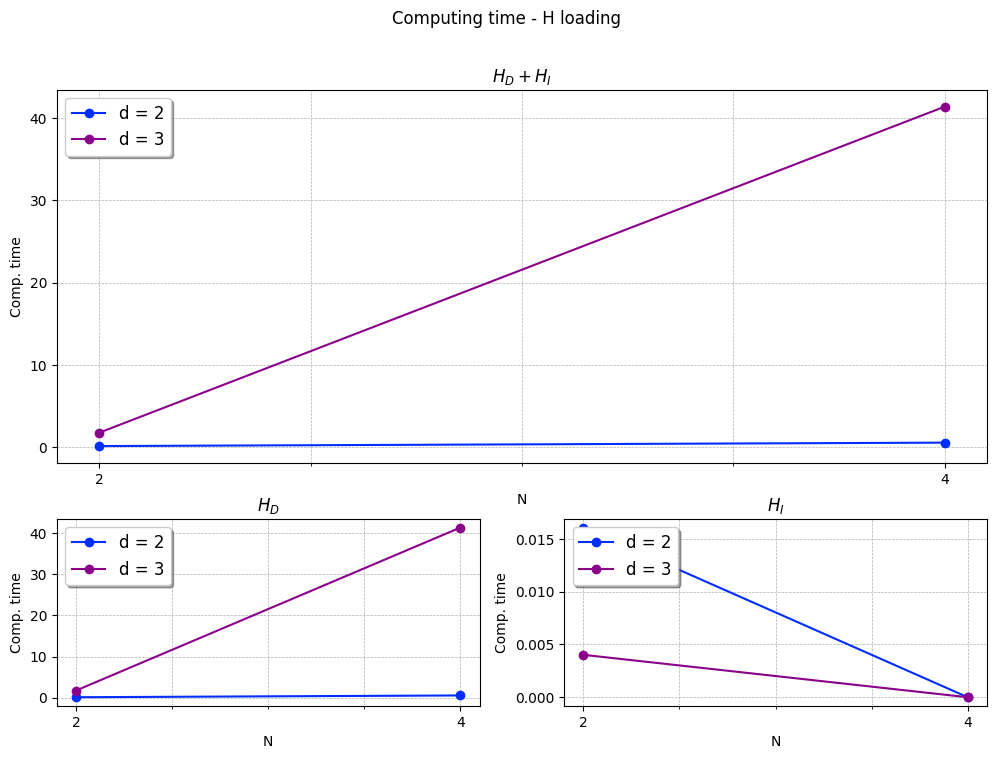

In [ ]:
Plotter.load_comptime_loadH("sim3")

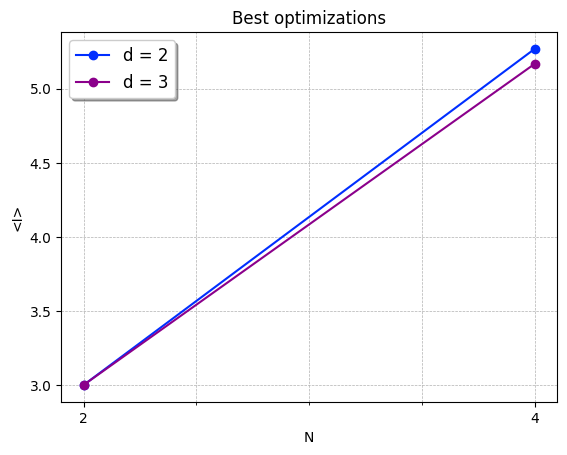

In [ ]:
Plotter.load_best_infidelities("sim3")

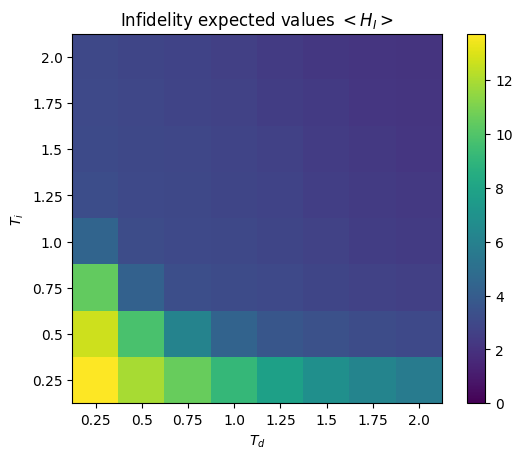

In [ ]:
Plotter.load_heatmap("sim3",6,2)

In [ ]:
class CircuitOperations:
    """
    Defines operations on circuit quantum states. Expose methods to calculate Driving and Infidelity hamiltonans 
    and run the optimization simulation.
    
    Parameters
    ------------
    shape : CircuitShape
        Shape of reference.

    Attributes
    -----------
    _shape : CircuitShape
        Shape of reference.
    _hops : np.matrix[]
        Matrix containing all hop operators, e.g. |n><m| to move from state |m> to state |n>. Thtese operators are represented by scipy.sparse._csr.csr_matrix type
    _Hd : scipy.sparse._csr.csr_matrix
        Driving hamiltonian.
    _Hi : scipy.sparse._csr.csr_matrix
        Infidelity hamiltonian.
    """
    def __init__(self,shape):  
        self._shape = shape
        self._hops = np.zeros((len(shape._steps),len(shape._steps)),dtype=object)
        self._Hd = None
        self._Hi = None
        for i in range(len(shape._steps)):
            for j in range(len(shape._steps)):
                self._hops[i,j] = sp.csr_matrix( np.kron(
                    np.conj(shape.state_of_step(shape._steps[j])).reshape(-1,1),
                    shape.state_of_step(shape._steps[i])
                ), dtype=np.cfloat)
    
    def get_H_eps(self,ids1,ids2,n_steps):
        """
        Calculates Hd_eps given an equivalence and the number of steps of the target circuits.

        Returns
        -------
        Hd_eps : scipy.sparse._csr.csr_matrix
        """
        id = sp.identity(len(self._hops), format='csr')
        H_eps = sp.csr_matrix((len(self._hops)**n_steps,len(self._hops)**n_steps), dtype=np.cfloat)
        for i_eq in range(0,n_steps+1-len(ids1)):
            H_eps_i = sp.identity(1,format='csr') 
            for i in range(0,i_eq):
                H_eps_i = sp.kron(H_eps_i,id)
            for i in range(0,len(ids1)):
                H_eps_i = sp.kron(H_eps_i,self._hops[ids1[i],ids2[i]])
            for i in range(i_eq+len(ids1),n_steps):
                H_eps_i = sp.kron(H_eps_i,id)
            H_eps += H_eps_i
        
        return H_eps + H_eps.getH()
    def get_Hd(self, dmax, n_steps):
        """
        Calculates Hd given a max equivalence order and the number of steps of
        the target circuits, loading equivalences from _shape._eq_dir files.

        Returns
        -------
        Hd : scipy.sparse._csr.csr_matrix
        """
        Hd = sp.csr_matrix((len(self._hops)**n_steps,len(self._hops)**n_steps), dtype=np.cfloat)
        for d in range(2,dmax+1):
            filename = f"{self._shape._eq_dir}/eq_d={d}.csv"
            with open(filename, 'r', newline='') as fin:
                reader = csv.reader(fin, delimiter="\t")
                #skips the header
                row = None
                while(row != "equivalences:"):
                    row = next(reader)[0]
                
                for row in reader:
                    ids1 = [int(id) for id in row[:d]]
                    ids2 = [int(id) for id in row[d:]]
                    Hd += self.get_H_eps(ids1,ids2,n_steps)
        return Hd
    def get_Hi(self, n_steps):
        """
        Calculates Hi the number of steps of the target circuits.

        Returns
        -------
        Hi : scipy.sparse._csr.csr_matrix
        """
        if self._shape._infidelities is None: raise Exception("Infidelities not provided in shape's constructor")
        Hi_step = sp.csr_matrix((self._shape.get_n_steps(),self._shape.get_n_steps()), dtype=np.cfloat)
        for i in range(self._shape.get_n_steps()):
            Hi_step += self._shape._infidelities[i] * self._hops[i,i]
        
        id = sp.identity(self._shape.get_n_steps(), format='csr')
        Hi= sp.csr_matrix((self._shape.get_n_steps()**n_steps,self._shape.get_n_steps()**n_steps), dtype=np.cfloat)
        for i in range(n_steps):
            Hi_i = sp.identity(1,format='csr') 
            for _ in range(0,i):
                Hi_i = sp.kron(Hi_i,id)
            Hi_i = sp.kron(Hi_i,Hi_step)
            for _ in range(0,n_steps-i-1):
                Hi_i = sp.kron(Hi_i,id)
            Hi+= Hi_i
        
        return Hi
    
    def multiply(operator,circuit_state):
        """
        Applies the operator to the state of the given circuit and returns
        a CircuitState with the result as state.

        Returns
        -------
        result_circuit : CircuitState
        """
        final_state = operator.dot(circuit_state._state)
        return CircuitState(circuit_state._shape,state=final_state)
    
    def expected_value_from_state(operator, state):
        """
        Returns the expected value of the given operator for the given state.

        Returns
        -------
        expected_value : float
        """
        expected_value = np.vdot(state,operator.dot(state))
        if expected_value.imag > 1e-12: raise Exception("The excpeted value is not real.")
        return expected_value.real
    def dev_std_from_state(operator,state):
        """
        Returns the standard deviation of the given operator for the given state.

        Returns
        -------
        std_dev : float
        """
        return np.sqrt( CircuitOperations.expected_value_from_state(operator.dot(operator),state) - CircuitOperations.expected_value_from_state(operator,state)**2 ) 
    def expected_value(operator,circuit_state):
        return CircuitOperations.expected_value_from_state(operator, circuit_state._state)
    def dev_std(operator, circuit_state):
        return CircuitOperations.dev_std_from_state(operator, circuit_state._state)
    def infidelity(self,circuit_state):
        """
        Returns infidelity expected value for the given circuit state.

        Returns
        -------
        normalized_state : np.array[]
        """
        if self._Hi is None: raise Exception("Hamiltonians not loaded")
        return CircuitOperations.expected_value(self._Hi, circuit_state).real
    def infidelity_from_statedict(state_dict):
        """
        Returns the expected value of the given operator for the given state dict, where key are infidelity
        values and entries the corresponding probability.

        Returns
        -------
        expected_value : float
        """
        return sum([inf*state_dict[inf] for inf in state_dict.keys()])
    def infidelity_err_from_statedict(state_dict):
        """
        Returns the standard deviation of the given operator for the given state dict, where key are infidelity
        values and entries the corresponding probability.

        Returns
        -------
        std_dev : float
        """
        return np.sqrt(sum([inf**2*state_dict[inf] for inf in state_dict.keys()]) - CircuitOperations.infidelity_from_statedict(state_dict)**2)
    
    def normalize(state):
        """
        Normalizes a vector state.

        Returns
        -------
        normalized_state : np.array[]
        """
        return state/np.sqrt(sum(np.abs(state)**2))
    
    def load_H(self,dmax, n_steps,get_comp_time=False):
        """
        Calculates and stores as attributes Hd and Hi. This method must be called before performing a simultaion.
        """
        if not get_comp_time:
            self._Hd = self.get_Hd(dmax,n_steps)
            self._Hi = self.get_Hi(n_steps)
        else:
            start_time_d = time.time()
            self._Hd = self.get_Hd(dmax,n_steps)
            end_time_d = time.time()
            self._Hi = self.get_Hi(n_steps)
            end_time_i = time.time()
            
            return (end_time_d-start_time_d, end_time_i-end_time_d)
    def delete_H():
        """
        Resets _Hd and _Hi attributes.
        """
        self._Hd = None
        self._Hi = None
        
    def simulate(self,circuit_state,Td=1,Nd=4,Ti=1,Ni=4,plot=False,verbose=False,get_comp_time=False,prob_treshold=None):
        if self._Hd is None or self._Hi is None: raise Exception("Hamiltonians not loaded.")
        if not circuit_state.is_classical(): raise Exception("Input state not classical.")
        
        dt_d = Td/Nd
        dt_i = Ti/Ni
        
        state = circuit_state.get_state()
        i_start = np.where(state!=0)[0][0]
        
        if prob_treshold is None: prob_treshold = 1/len(state)
        
        start_time = time.time()
        evolution_d = sp.linalg.expm_multiply(-1j*self._Hd,state, start=0, stop=Td, num=Nd+1, endpoint=True)
        evolution_i = sp.linalg.expm_multiply(-1*self._Hi, evolution_d[-1], start=0, stop=Ti, num=Ni+1, endpoint=True)
        end_time = time.time()
        evolution_i = [CircuitOperations.normalize(step) for step in evolution_i]
        
        population_d = [len(np.where(np.abs(state)**2>prob_treshold)[0]) for state in evolution_d]
        population_i = [len(np.where(np.abs(state)**2>prob_treshold)[0]) for state in evolution_i]
        # if verbose:
        #     for i in range(len(evolution_d)): 
        #         print("t:",t_d[i])
        #         [print(full_index) for full_index in CircuitState(circuit_state._shape,state=evolution_d[i]).get_full_indexes()]
        
        p0 = np.abs([state[i_start] for state in evolution_d])**2
        
        if plot: 
            expected_values_d = [CircuitOperations.expected_value_from_state(self._Hi,state) for state in evolution_d]
            expected_values_i = [CircuitOperations.expected_value_from_state(self._Hi,state) for state in evolution_i]
            dev_stds_d = [CircuitOperations.dev_std_from_state(self._Hi,state) for state in evolution_d]
            dev_stds_i = [CircuitOperations.dev_std_from_state(self._Hi,state) for state in evolution_i]
        
            Plotter.plot_evolution(dt_d,dt_i,Nd+1,Ni+1,expected_values_d,expected_values_i,dev_stds_d,dev_stds_i,p0,population_d + population_i)
        
        if not get_comp_time:
            return (evolution_d,evolution_i,population_d,population_i,p0)
        else:
            return (evolution_d,evolution_i,population_d,population_i,p0,end_time-start_time)
        
    def final_simulation(self, circuit_state, dt, Td_max, Ti_max, N_list, d_list, plot=False, start_directory="./"):
        if not circuit_state.is_classical(): raise Exception("Input state not classical.")
        
        comp_times_loadH = []
        comp_times_sims = []
        bests = []
        
        Nd = int(Td_max/dt)
        Ni = int(Ti_max/dt)
        
        start_state = np.array([1],dtype=np.cdouble)
        
        dir = start_directory + f"simulation_{datetime.datetime.now().strftime('%Y-%m-%d_%H-%M-%S')}"
        dir = "sim3"
        # os.makedirs(dir, exist_ok=False)
        os.makedirs(dir, exist_ok=True)
        
        FileWriter.save_descr_file(dir,circuit_state,Td_max,Ti_max,dt,N_list,d_list)
        
        for N in N_list:
            start_state = np.kron(start_state,circuit_state.get_state()) 
            
            print("N:",N,CircuitState(self._shape,state=start_state).draw())
            
            prob_treshold = 1/len(start_state)
            
            comp_times_loadH.append([])
            comp_times_sims.append([])
            bests.append([])
            for d in d_list:
                print(f"Loading H for N={N},d={d}...")
                comp_time_loadH = self.load_H(d,N,get_comp_time=True)
                comp_times_loadH[-1].append(comp_time_loadH)
                print(f"Loaded in " + "{:.3f}".format((comp_time_loadH[0]+comp_time_loadH[1])*1e3) + "ms.\n")
                infidelities = []
                best = (math.inf,0,0)  #inf,Td_index,Ti_index
                
                # simulation over all the possible Td,Ti
                print("Starting test simulations...")
                evolution_d = sp.linalg.expm_multiply(-1j*self._Hd,start_state, start=dt, stop=Td_max, num=Nd, endpoint=True)
                for i in range(Nd):
                    evolution_i = sp.linalg.expm_multiply(-1*self._Hi, evolution_d[i], start=dt, stop=Ti_max, num=Ni, endpoint=True)
                    evolution_i = [CircuitOperations.normalize(step) for step in evolution_i]
                    inf_i = [CircuitOperations.expected_value_from_state(self._Hi,state) for state in evolution_i]
                    infidelities.append(inf_i)
                    
                    inf_min_index = np.where(inf_i == min(inf_i))[0]
                    if inf_i[inf_min_index[0]] < best[0]:    #the first one minimizes Ti
                        best = (inf_i[inf_min_index[0]],i,inf_min_index[0])
                    elif inf_i[inf_min_index[0]] == best[0] and i+inf_min_index[0]<best[1]+best[2]: #only works if dt is the same for both Td and Ti
                        best = (inf_i[inf_min_index[0]],i,inf_min_index[0])
                print("Test simulation over.\n")
                bests[-1].append(best)
                
                #print("Saving infidelities...")
                # FileWriter.save_heatmap(dir,N,d,Td_max,Ti_max,dt,infidelities)
                if plot:            
                    Plotter.plot_infidelities_heatmap(infidelities,Td_max,Ti_max,dt)
                del infidelities
                # print("Infidelities saved.\n")
                # simulation on the best
                Td = (best[1]+1)*dt
                Ti = (best[2]+1)*dt
                print(f"\nStarting simulation with best parameters (Td={Td}s,Ti={Ti}s) ...")
                N_best = 10
                evolution_d,evolution_i,population_d,population_i,p0, comp_time = self.simulate(CircuitState(circuit_state._shape, state = start_state), (best[1]+1)*dt, N_best, (best[2]+1)*dt, N_best, get_comp_time=True, plot=True, prob_treshold=prob_treshold)
                print("Simulation over.\n")
                comp_times_sims[-1].append(comp_time)
                
                # print("Saving best simulation...")
                # evolution_dicts = []
                # for step in np.concatenate((evolution_d,evolution_i)):
                #     state_dict = {}
                #     for i in range(len(step)):
                #         if np.abs(step[i])**2 > 1e-8:
                #             s = np.zeros((len(step)))
                #             s[i] = 1.
                #             infidelity = sum([circuit_state._shape._infidelities[timestep] for timestep in CircuitState(circuit_state._shape,state=s).get_full_indexes()[0]])
                            
                #             if infidelity not in state_dict.keys():
                #                 state_dict[infidelity] = np.abs(step[i])**2
                #             else:
                #                 state_dict[infidelity] += np.abs(step[i])**2
                #     evolution_dicts.append(state_dict)
                # FileWriter.save_best(dir,N,d,Td,Ti,Td/N_best,Ti/N_best,N_best,N_best,evolution_dicts,p0,population_d + population_i)
                # print("Best simulation saved.\n")
                # if plot:
                #     evolution_dict_d = evolution_dicts[:len(evolution_d)]
                #     evolution_dict_i = evolution_dicts[len(evolution_d):]
                #     expected_values_d = [CircuitOperations.infidelity_from_statedict(state_dict) for state_dict in evolution_dict_d]
                #     expected_values_i = [CircuitOperations.infidelity_from_statedict(state_dict) for state_dict in evolution_dict_i]
                #     dev_stds_d = [CircuitOperations.infidelity_err_from_statedict(state_dict) for state_dict in evolution_dict_d]
                #     dev_stds_i = [CircuitOperations.infidelity_err_from_statedict(state_dict) for state_dict in evolution_dict_i]

                #     p0 = np.abs([state[np.where(start_state!=0)[0][0]] for state in evolution_d])**2
                #     Plotter.plot_evolution(Td/N_best,Ti/N_best,N_best+1,N_best+1,expected_values_d,expected_values_i,dev_stds_d,dev_stds_i,p0,np.concatenate((population_d,population_i)))
        print(comp_times_loadH)
        Plotter.plot_comptime_loadH(N_list,d_list,comp_times_loadH)
        Plotter.plot_comptime_bestsims(N_list,d_list,comp_times_sims)
        Plotter.plot_bests(N_list,d_list,bests)
        # FileWriter.save_comptime_loadH(dir,N_list,d_list,comp_times_loadH)
        # FileWriter.save_comptime_bestsims(dir,N_list,d_list,comp_times_sims)
        # FileWriter.save_best_infidelities(dir,N_list,d_list,bests)

In [ ]:
op = CircuitOperations(shape)
c_start = CircuitState.from_steps_ids([3,13],shape)
c_start.draw()

q_0: ────■────
         │    
q_1: ─X──┼──■─
      │  │  │ 
q_2: ─X──■──┼─
            │ 
q_3: ───────■─

N: 2               
q_0: ────■────
         │    
q_1: ─X──┼──■─
      │  │  │ 
q_2: ─X──■──┼─
            │ 
q_3: ───────■─
              
Loading H for N=2,d=2...
Loaded in 178.601ms.

Starting test simulations...
Test simulation over.



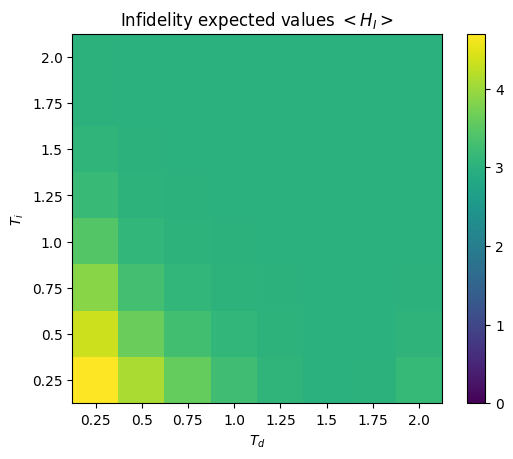


Starting simulation with best parameters (Td=1.5s,Ti=2.0s) ...


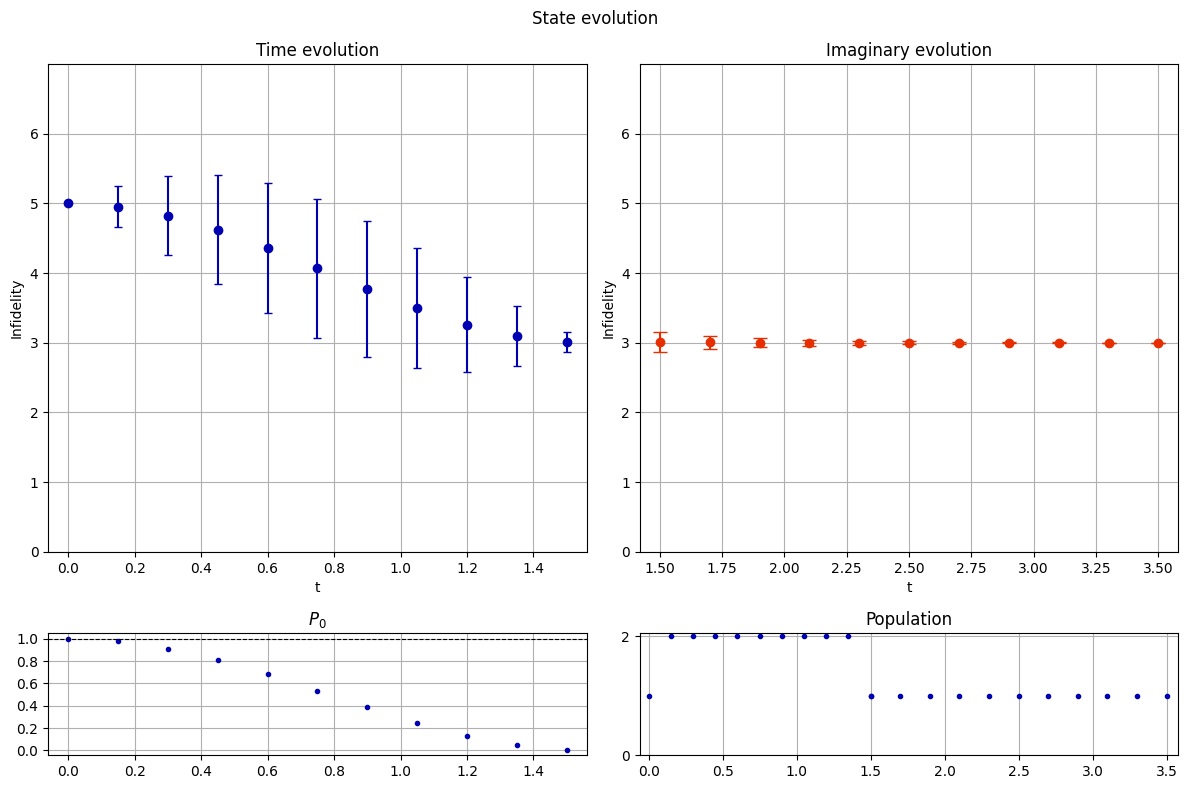

Simulation over.

Loading H for N=2,d=3...
Loaded in 2719.167ms.

Starting test simulations...
Test simulation over.



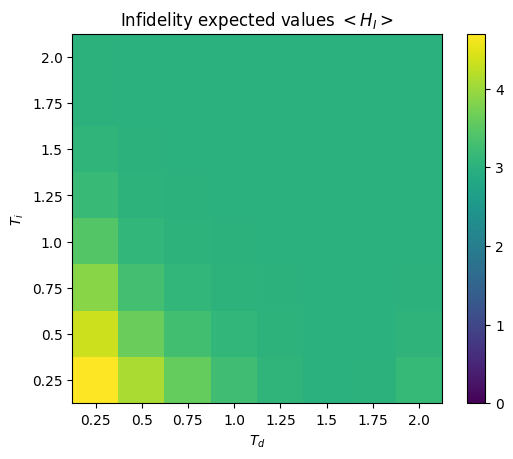


Starting simulation with best parameters (Td=1.5s,Ti=2.0s) ...


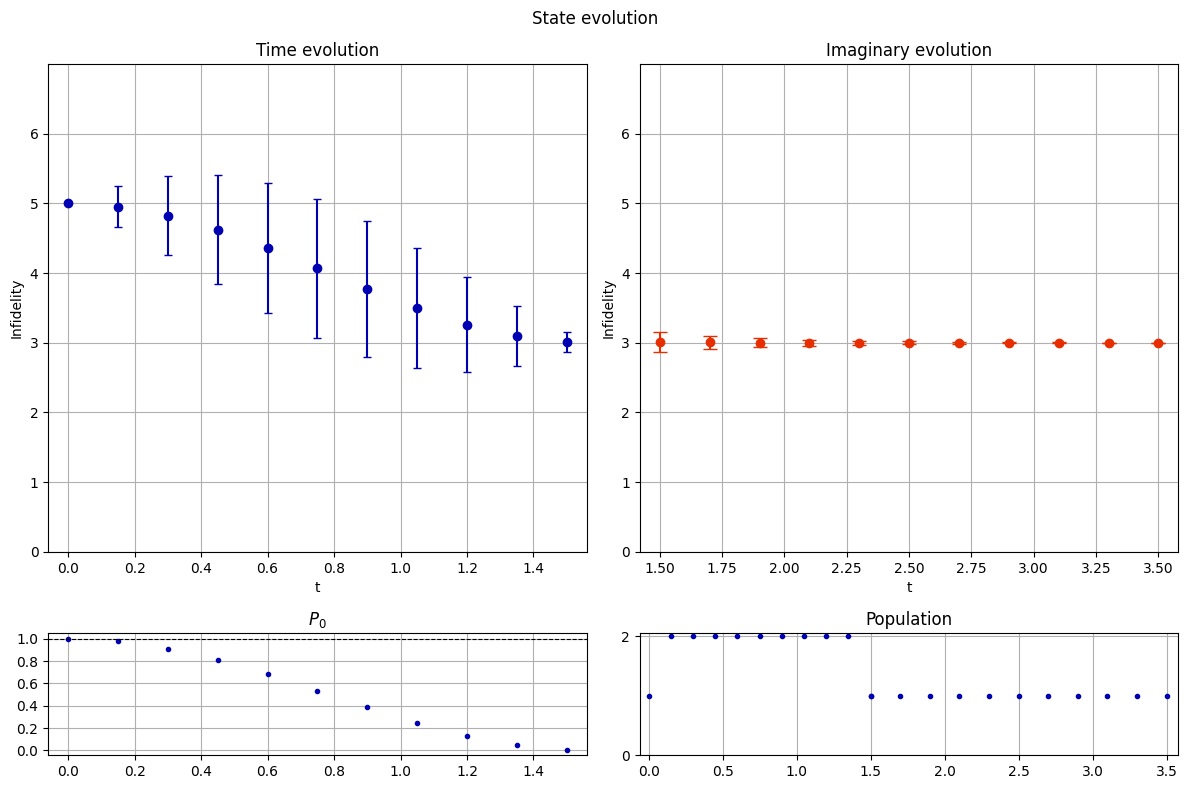

Simulation over.

N: 4                        
q_0: ────■────────■────
         │        │    
q_1: ─X──┼──■──X──┼──■─
      │  │  │  │  │  │ 
q_2: ─X──■──┼──X──■──┼─
            │        │ 
q_3: ───────■────────■─
                       
Loading H for N=4,d=2...
Loaded in 923.435ms.

Starting test simulations...
Test simulation over.



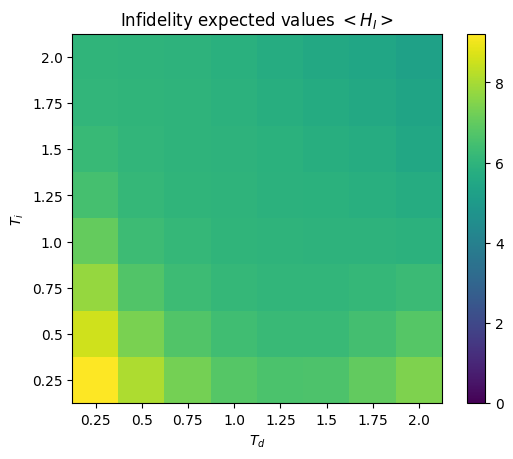


Starting simulation with best parameters (Td=2.0s,Ti=2.0s) ...


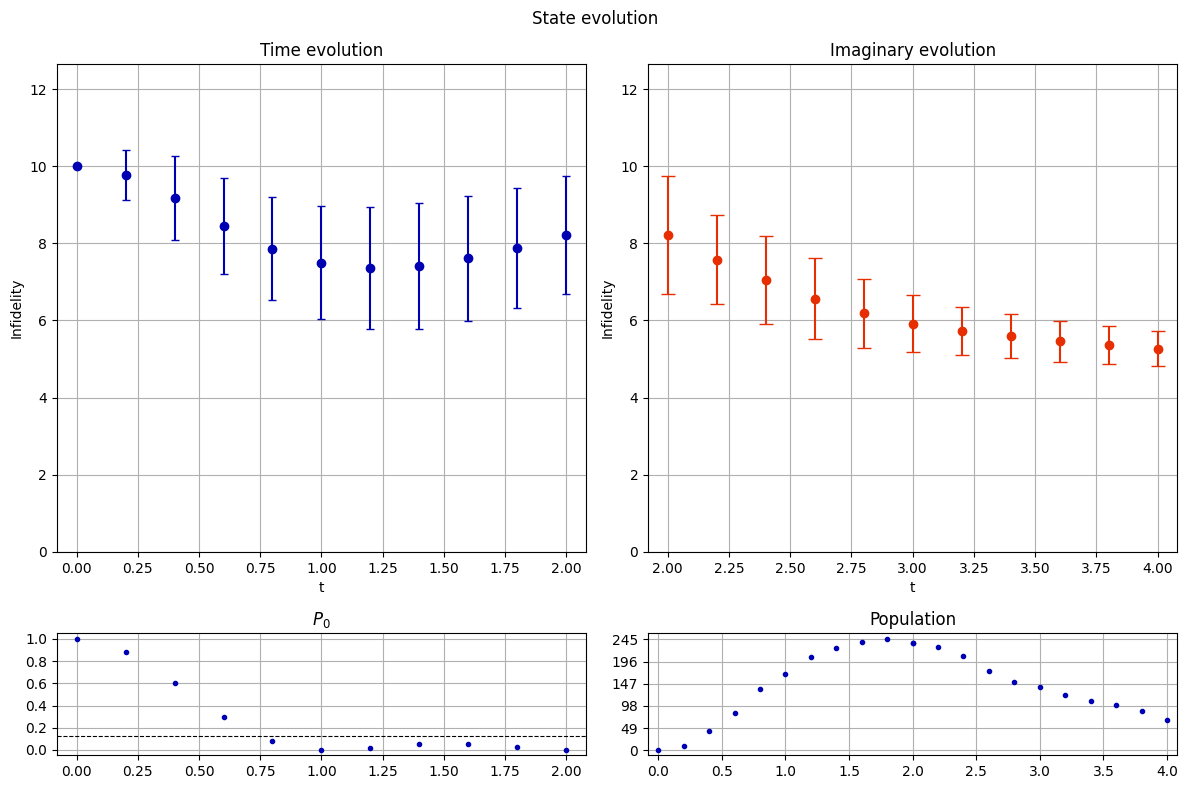

Simulation over.

Loading H for N=4,d=3...
Loaded in 46604.911ms.

Starting test simulations...
Test simulation over.



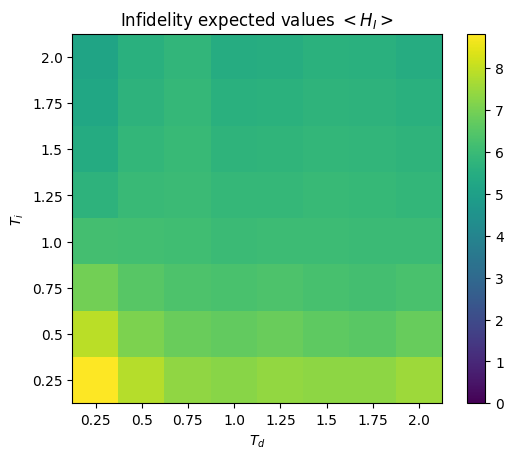


Starting simulation with best parameters (Td=0.25s,Ti=2.0s) ...


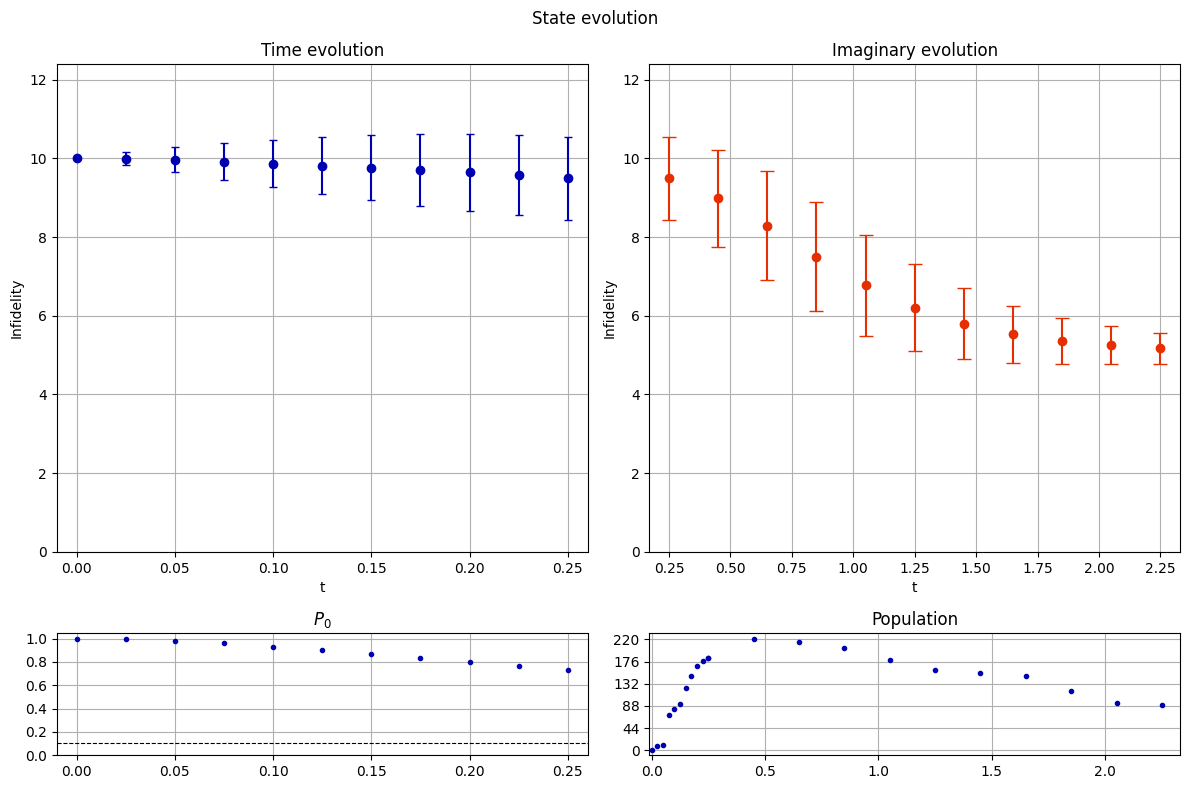

Simulation over.

N: 6                                 
q_0: ────■────────■────────■────
         │        │        │    
q_1: ─X──┼──■──X──┼──■──X──┼──■─
      │  │  │  │  │  │  │  │  │ 
q_2: ─X──■──┼──X──■──┼──X──■──┼─
            │        │        │ 
q_3: ───────■────────■────────■─
                                
Loading H for N=6,d=2...
Loaded in 71694.676ms.

Starting test simulations...
Test simulation over.



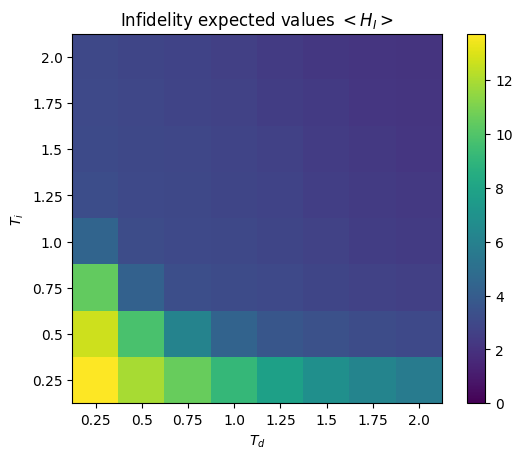


Starting simulation with best parameters (Td=2.0s,Ti=2.0s) ...


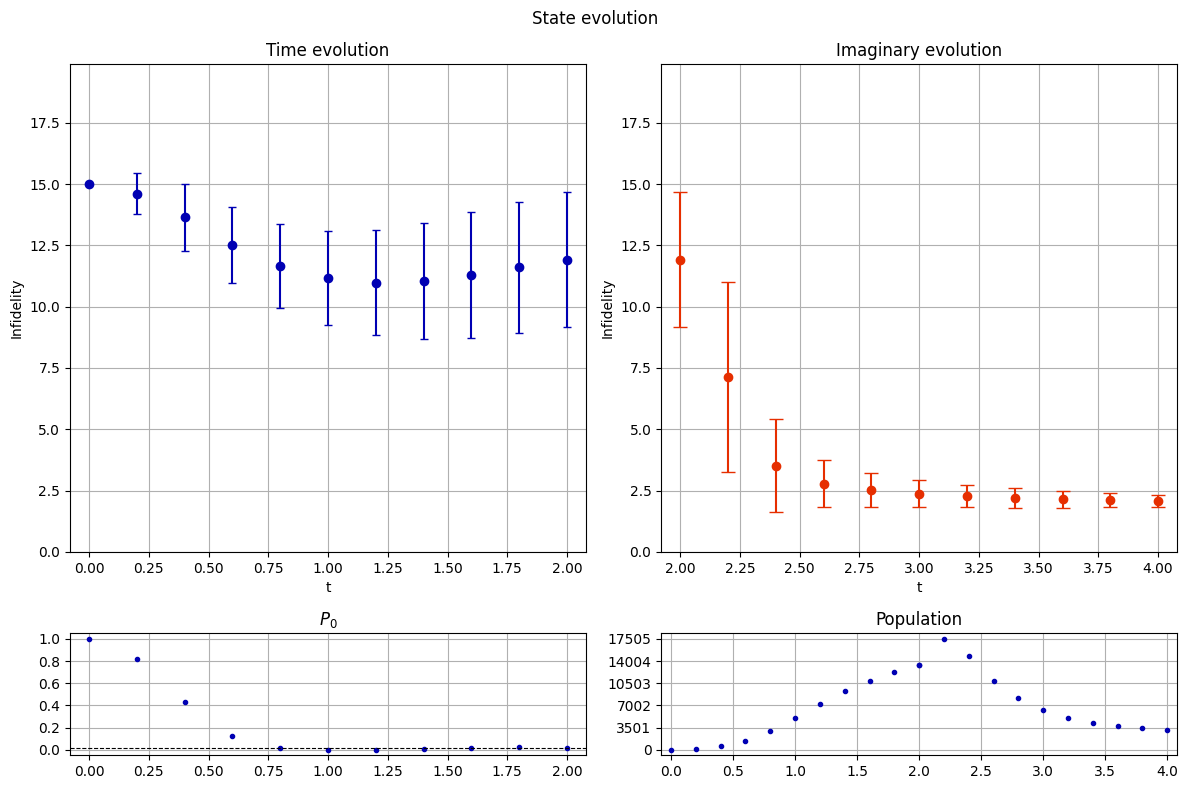

Simulation over.

Loading H for N=6,d=3...


KeyboardInterrupt: 

In [ ]:
op.final_simulation(c_start,0.25,2,2,[2,4,6],[2,3], plot=True)

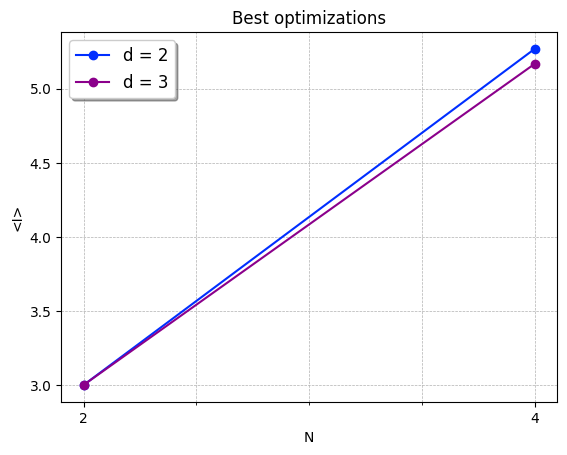

In [ ]:
Plotter.load_best_infidelities("sim3")

In [ ]:
Plotter.